
# Scouting Geométrico

**Objetivo:** Encontrar al jugador mas parecido a nuestra estrella utilizando estadsticas de la temporada 2025-2026.

Compararemos jugadores mediante distancias euclidianas y Manhattan, y despuees visualizaremos su estadisticas..


In [11]:

import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/mricardo89/data-mining/main/Unit-III/datasets/players_data-2025_2026.csv"

df = pd.read_csv(url)

print("Jugadores/registros:", len(df))
display(df[["Player", "Gls", "Ast", "Min", "Sh/90"]].head())


Jugadores/registros: 2839


,Player,Gls,Ast,Min,Sh/90
0,Brenden Aaronson,4,5,2449,1.73
1,Jerome Abbey,0,0,17,0.00
2,Zach Abbott,0,0,164,0.00
3,Jones El-Abdellaoui,2,0,681,2.25
4,Himad Abdelli,0,0,138,2.61


In [4]:

caracteristicas = ["Gls", "Ast", "Min", "Sh/90"]

# seleccionar columnas necesarias
jugadores = df[["Player", "Squad", "Pos"] + caracteristicas].copy()

#convertir estadisticas a float
for columna in caracteristicas:
    jugadores[columna] = pd.to_numeric(
        jugadores[columna], errors="coerce"
    ).astype(float)

# Eliminar registros incompletos
jugadores = jugadores.dropna(subset=caracteristicas).reset_index(drop=True)

# elegir jugador con mas goles
indice_estrella = jugadores["Gls"].idxmax()
estrella = jugadores.loc[indice_estrella]

print("Jugador estrella:", estrella["Player"])
display(jugadores.loc[[indice_estrella]])


Jugador estrella: Harry Kane


,Player,Squad,Pos,Gls,Ast,Min,Sh/90
1319,Harry Kane,Bayern Munich,"FW,MF",36.0,5.0,2377.0,4.51



### Pregunta de control

**¿Qué operación debemos aplicar antes de calcular las distancias?**

Debemos aplicar una estandarización Z-Score para que todas las características tengan una escala comparable. Esto evita que los minutos jugados tengan mayor peso que los goles solamente porque sus valores son mucho más grandes.


In [6]:

# Matriz con las 4 caracteristicas
X = jugadores[caracteristicas].astype(float)

# Estandarizacion Z-Score
X = (X - X.mean()) / X.std(ddof=0)

# vector del jugador estrella
vector_estrella = X.loc[indice_estrella].to_numpy()

# vectores de los demas candidatos
candidatos = jugadores.drop(index=indice_estrella)
vectores_candidatos = X.drop(index=indice_estrella).to_numpy()

print("Vector estrella:", vector_estrella)
print("Matriz X:", X.shape)
print("Vectores candidatos:", vectores_candidatos.shape)


Vector estrella: [11.71130618  2.09565212  1.20286658  1.29584932]
Matriz X: (2839, 4)
Vectores candidatos: (2838, 4)



## 2. Distancia Euclidiana vs Manhattan

La distancia euclidiana mide la distancia en línea recta entre dos vectores.

La distancia Manhattan suma las diferencias absolutas de cada característica, como si recorriéramos las calles de una ciudad.

**Fórmula Manhattan:**

$$d(x,y) = \sum_{i=1}^{n}|x_i-y_i|$$

Donde $x$ y $y$ son los vectores de dos jugadores, y $n$ es el número de características que estamos comparando.


In [8]:

# Calcular distancias euclidianas
distancias_eu = np.linalg.norm(
    vectores_candidatos - vector_estrella, axis=1
)

# Encontrar al mass cercano
indice_eu = np.argmin(distancias_eu)
reemplazo_eu = candidatos.iloc[indice_eu]

print("Jugador estrella:", estrella["Player"])
print("Reemplazo Euclidiano:", reemplazo_eu["Player"])
print("Distancia:", round(distancias_eu[indice_eu], 4))


Jugador estrella: Harry Kane
Reemplazo Euclidiano: Erling Haaland
Distancia: 3.5402


In [9]:

# funcion personalizada para distancia manhattan
def distancia_manhattan(a, b):
    return np.sum(np.abs(a - b))

# calcular distancias de todos los candidatos
distancias_man = np.array([
    distancia_manhattan(vector_estrella, candidato)
    for candidato in vectores_candidatos
])

# encontrar al mas cercano
indice_man = np.argmin(distancias_man)
reemplazo_man = candidatos.iloc[indice_man]

print("Jugador estrella:", estrella["Player"])
print("Reemplazo Manhattan:", reemplazo_man["Player"])
print("Distancia:", round(distancias_man[indice_man], 4))


Jugador estrella: Harry Kane
Reemplazo Manhattan: Kylian Mbappé
Distancia: 4.2067


In [10]:

print("Euclidiana:", reemplazo_eu["Player"])
print("Manhattan:", reemplazo_man["Player"])

if reemplazo_eu["Player"] == reemplazo_man["Player"]:
    print("Ambos métodos sugirieron al mismo jugador.")
else:
    print("Los métodos sugirieron jugadores diferentes.")


Euclidiana: Erling Haaland
Manhattan: Kylian Mbappé
Los métodos sugirieron jugadores diferentes.



### Análisis crítico

Los dos algoritmos nos dieron resultados diferentes. La distancia Euclidiana sugirió a Erling Haaland como reemplazo de Harry Kane, mientras que Manhattan sugirió a Kylian Mbappé.

Esto sucede porque Euclidiana penaliza más las diferencias grandes entre las estadísticas, mientras que Manhattan suma las diferencias absolutas de cada característica.

En este caso elegiría a Haaland porque fue el jugador más cercano utilizando la distancia Euclidiana. Sin embargo, esto no significa que sea exactamente igual a Kane, solamente que sus estadísticas son las más parecidas según las características que seleccionamos.



## Fase 3. Visualización en 4D

Para representar nuestras 4 dimensiones elegimos utilizar Coordenadas Paralelas con Pandas y Matplotlib.

Esta técnica permite mostrar varias características en una gráfica 2D, donde cada línea representa un jugador y cada eje vertical corresponde a una estadística.

Compararemos a Harry Kane, Erling Haaland y un tercer jugador aleatorio para observar qué tan similares son sus estadísticas.

**Fuente:** https://pandas.pydata.org/docs/reference/api/pandas.plotting.parallel_coordinates.html


In [12]:

import matplotlib.pyplot as plt
from pandas.plotting import parallel_coordinates

# Elegir un tercer jugador aleatorio
tercero = candidatos.drop(index=reemplazo_eu.name).sample(
    random_state=42
).iloc[0]

# Obtener las estadisticas estandarizadas de los 3 jugadores
comparacion = X.loc[
    [indice_estrella, reemplazo_eu.name, tercero.name],
    caracteristicas
].copy()

comparacion["Jugador"] = [
    estrella["Player"],
    reemplazo_eu["Player"],
    tercero["Player"]
]

print("Tercer jugador:", tercero["Player"])
display(comparacion)


Tercer jugador: Sam Byram


,Gls,Ast,Min,Sh/90,Jugador
1319,11.711306,2.095652,1.202867,1.295849,Harry Kane
1104,8.641908,3.732544,1.800967,1.022164,Erling Haaland
415,-0.566285,-0.632501,-1.255990,-0.546419,Sam Byram


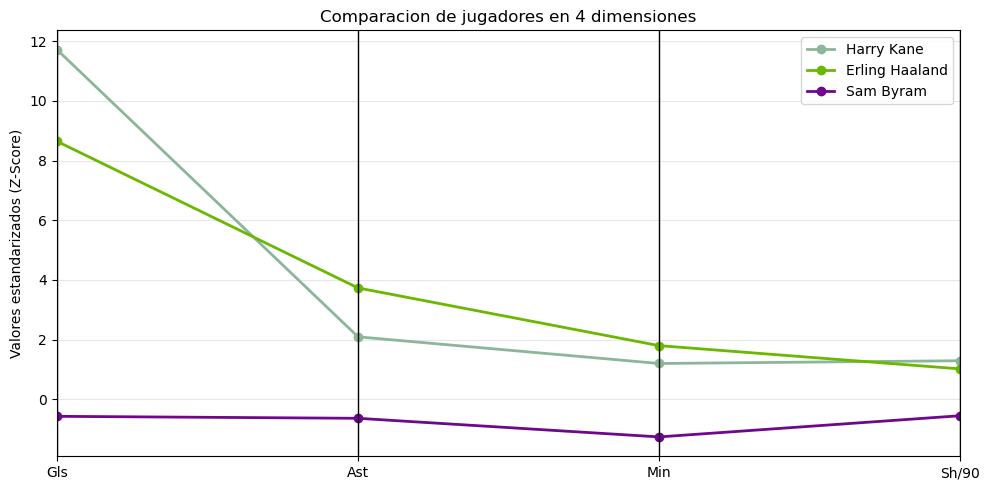

In [13]:

# Graficar las 4 dimensiones en 2D
plt.figure(figsize=(10, 5))

parallel_coordinates(
    comparacion,
    "Jugador",
    cols=caracteristicas,
    marker="o",
    linewidth=2
)

plt.title("Comparacion de jugadores en 4 dimensiones")
plt.ylabel("Valores estandarizados (Z-Score)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:

# Distancia entre Kane y el tercer jugador
distancia_tercero = np.linalg.norm(
    X.loc[tercero.name].to_numpy() - vector_estrella
)

print("Estrella:", estrella["Player"])
print("Reemplazo:", reemplazo_eu["Player"])
print("Tercer jugador:", tercero["Player"])

print("Distancia al reemplazo:", round(distancias_eu[indice_eu], 4))
print("Distancia al tercer jugador:", round(distancia_tercero, 4))


Estrella: Harry Kane
Reemplazo: Erling Haaland
Tercer jugador: Sam Byram
Distancia al reemplazo: 3.5402
Distancia al tercer jugador: 12.9469



### Conclusion

Con la gráfica de coordenadas paralelas pudimos comparar las 4 estadísticas de los jugadores en una sola visualización.

El algoritmo encontró que Erling Haaland es el jugador más cercano a Harry Kane usando distancia Euclidiana. Al compararlo con un tercer jugador aleatorio también podemos observar las diferencias entre sus estadísticas.

Aunque Haaland es el más parecido matemáticamente, esto no significa que juegue exactamente igual. Para un análisis más completo también tendríamos que considerar otras estadísticas y su posición en el campo.
